# RBIG Demo

In [1]:
!pip install python-picard
!pip install "git+https://github.com/IPL-UV/rbig.git"

import numpy as np
import warnings
from time import time

# from rbig.model import RBIG
from sklearn.model_selection import train_test_split
from sklearn.utils import check_random_state
import matplotlib.pyplot as plt
plt.style.use('ggplot')
warnings.filterwarnings('ignore') # get rid of annoying warnings

%matplotlib inline
%load_ext autoreload
%autoreload 2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for python-picard: filename=python_picard-0.8-py3-none-any.whl size=16394 sha256=caaebff3ee39eab7a24d6297b39dfe81d1d1c3f60f607344b7503fb8ec5fe69e
  Stored in directory: /root/.cache/pip/wheels/86/7e/fc/6183c6bfdc791d9e7b5a1df84ec4f30055f76bc8414ab2300d
Successfully built python-picard
  Cloning https://github.com/IPL-UV/rbig.git to /tmp/pip-req-build-hybus_qb
  Running command git clone --filter=blob:none --quiet https://github.com/IPL-UV/rbig.git /tmp/pip-req-build-hybus_qb
  Resolved https://github.com/IPL-UV/rbig.git to commit a9124fc07d8e851833802d604fe552b6327ab980
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 16.9 MB/s eta 0:00:00
  Created wheel for py_rbig: filename=py_rbig-0.0.1-py3-none-any.whl size=17468 sha256=fefab46e634135e81923d8d46cd88ad5d1579a2a1a3bcc827eb278536a192419
  Stored in dire

#### Toy Data

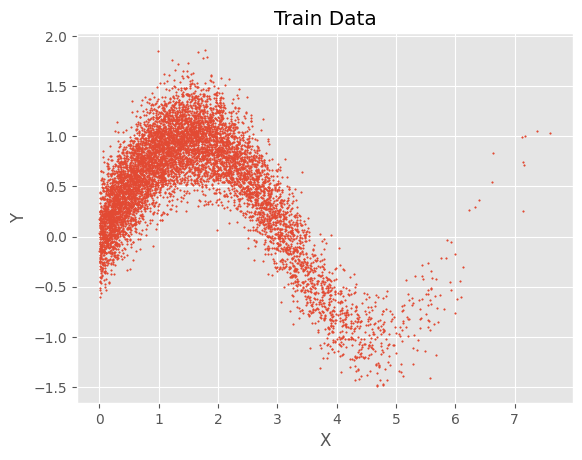

In [17]:
import sklearn

seed = 123
rng = np.random.RandomState(seed=seed)

num_samples = 10000
x = np.abs(2 * rng.randn(1, num_samples))
y = np.sin(x) + 0.25 * rng.randn(1, num_samples)
data = np.vstack((x, y)).T

# Train test
[x_tr, x_ts] =  sklearn.model_selection.train_test_split(data,test_size=0.2)

# plot
fig, ax = plt.subplots()
ax.scatter(x_tr[:, 0], x_tr[:, 1], s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Train Data')
plt.show()

## RBIG Fitting

In [3]:
%%time
from rbig import RBIG

rotation_type = 'pca'
n_layers = 1000
# Initialize RBIG class
rbig_model = RBIG(rotation = rotation_type,
                  max_layers = n_layers,)

# transform data
data_trans = rbig_model.fit_transform(x_tr)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 4.04 s, sys: 434 ms, total: 4.48 s
Wall time: 6.62 s


### Estimating Probabilities with RBIG

In [14]:
%%time
prob_input = rbig_model.predict_proba(x_ts)

# Calculamos el nivel de anomalia
# se le aplica una nolinealiedad monotónica a la probabilidad para exagerar el efecto
anomaly = 1-np.log(prob_input+1)**0.1

CPU times: user 46.8 ms, sys: 0 ns, total: 46.8 ms
Wall time: 47.1 ms


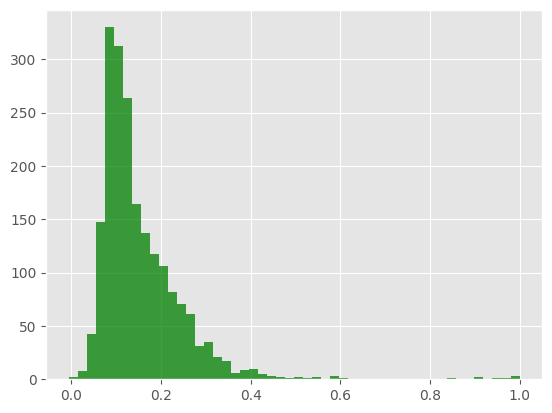

In [15]:
fig, ax = plt.subplots()
ax.hist(anomaly, 50, facecolor='green', alpha=0.75)
plt.show()

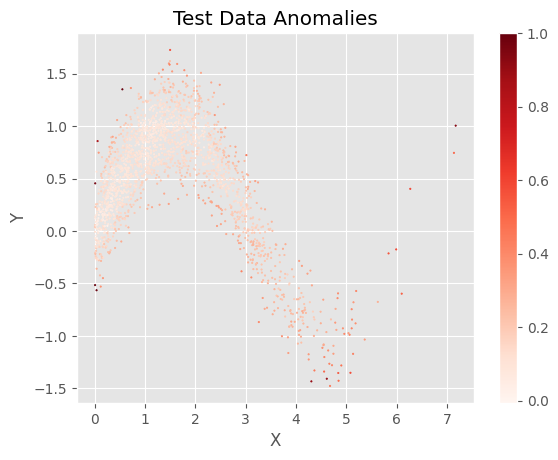

In [16]:
fig, ax = plt.subplots()


h = ax.scatter(x_ts[:, 0], x_ts[:, 1], s=1, c=anomaly, cmap='Reds')

ax.set_xlabel('X')
ax.set_ylabel('Y')
cbar = plt.colorbar(h, )
ax.set_title('Test Data Anomalies')
plt.show()